# **1. Perkenalan Dataset**


# 1. Perkenalan Dataset

Dataset yang digunakan dalam eksperimen ini adalah **Titanic - Machine Learning from Disaster**, yang diperoleh dari Kaggle.

Sumber dataset: https://www.kaggle.com/competitions/titanic/data

Dataset ini berisi informasi penumpang kapal Titanic, termasuk kelas tiket, jenis kelamin, usia, jumlah saudara atau pasangan yang ikut berlayar, jumlah orang tua atau anak, tarif tiket, pelabuhan keberangkatan, dan informasi kabin.

Tujuan eksperimen adalah membangun model klasifikasi untuk memprediksi kemungkinan penumpang selamat berdasarkan karakteristik yang tersedia. Variabel target yang digunakan adalah `Survived`, dengan nilai 0 yang berarti tidak selamat dan nilai 1 yang berarti selamat.

Dataset ini sesuai untuk eksperimen machine learning karena memiliki kombinasi fitur numerik dan kategorikal serta beberapa nilai yang hilang. Oleh karena itu, tahapan eksperimen mencakup data loading, Exploratory Data Analysis (EDA), pembersihan data, imputasi missing values, encoding fitur kategorikal, standardisasi fitur numerik, dan penyimpanan dataset hasil preprocessing untuk digunakan pada tahap pembangunan model.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [17]:
# Sesuaikan lokasi file dengan struktur folder Anda
df = pd.read_csv("/content/train.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [18]:
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

print("\nNama kolom:")
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,1601,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



Nama kolom:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

In [19]:
print("Missing values per kolom:")
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Jumlah Missing Values")
)

print("Jumlah baris duplikat:", df.duplicated().sum())

print("\nDistribusi target:")
display(df["Survived"].value_counts())

Missing values per kolom:


,Jumlah Missing Values
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


Jumlah baris duplikat: 0

Distribusi target:


,count
Survived,
0,549
1,342


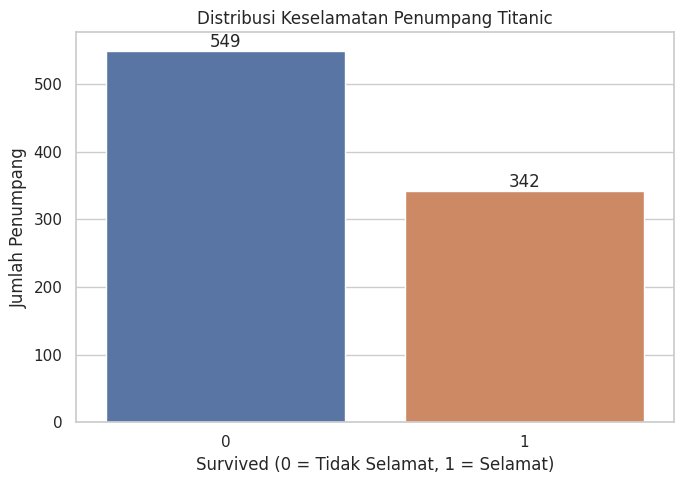

In [20]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Survived",
    hue="Survived",
    legend=False
)

ax.set_title("Distribusi Keselamatan Penumpang Titanic")
ax.set_xlabel("Survived (0 = Tidak Selamat, 1 = Selamat)")
ax.set_ylabel("Jumlah Penumpang")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

,Survival Rate (%)
Sex,
female,74.203822
male,18.890815


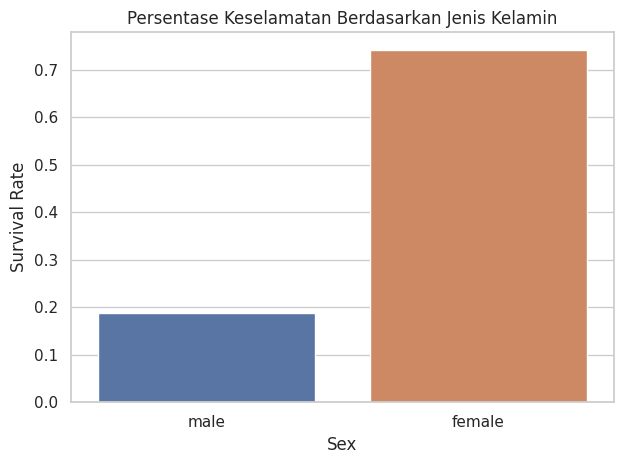

In [21]:
survival_by_sex = (
    df.groupby("Sex", observed=True)["Survived"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

display(survival_by_sex.to_frame("Survival Rate (%)"))

sns.barplot(
    data=df,
    x="Sex",
    y="Survived",
    hue="Sex",
    legend=False,
    errorbar=None
)

plt.title("Persentase Keselamatan Berdasarkan Jenis Kelamin")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

,Survival Rate (%)
Pclass,
1,62.962963
2,47.282609
3,24.236253


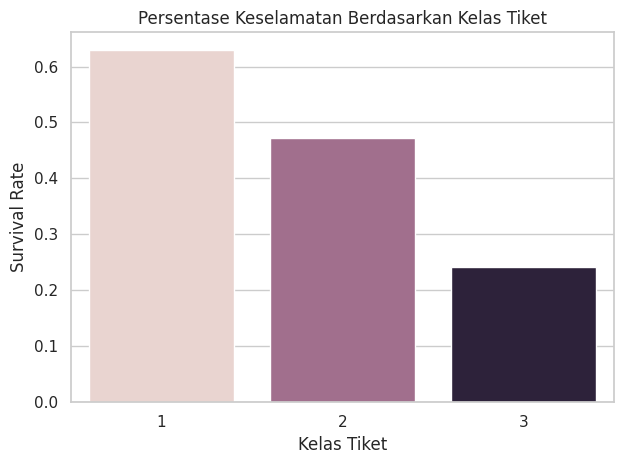

In [22]:
survival_by_class = (
    df.groupby("Pclass", observed=True)["Survived"]
      .mean()
      .mul(100)
)

display(survival_by_class.to_frame("Survival Rate (%)"))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Pclass",
    legend=False,
    errorbar=None
)

plt.title("Persentase Keselamatan Berdasarkan Kelas Tiket")
plt.xlabel("Kelas Tiket")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

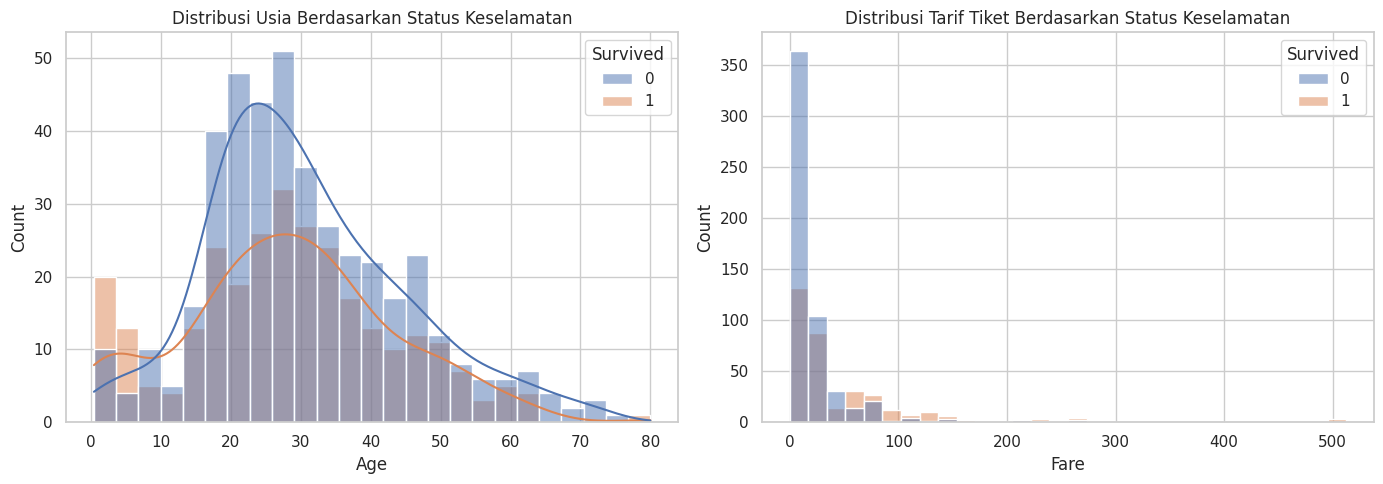

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=25,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribusi Usia Berdasarkan Status Keselamatan")

sns.histplot(
    data=df,
    x="Fare",
    hue="Survived",
    bins=30,
    ax=axes[1]
)
axes[1].set_title("Distribusi Tarif Tiket Berdasarkan Status Keselamatan")

plt.tight_layout()
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [24]:
df_clean = df.copy()

# Menghapus baris duplikat jika ada
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Menghapus kolom yang tidak digunakan dalam model dasar
columns_to_drop = ["PassengerId", "Name", "Ticket", "Cabin"]

df_clean = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Ukuran data setelah pembersihan:", df_clean.shape)
display(df_clean.head())

Ukuran data setelah pembersihan: (891, 8)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [25]:
X = df_clean.drop(columns=["Survived"])
y = df_clean["Survived"].astype(int)

print("Ukuran fitur:", X.shape)
print("Ukuran target:", y.shape)

print("\nTipe data fitur:")
display(X.dtypes.to_frame("Tipe Data"))

Ukuran fitur: (891, 7)
Ukuran target: (891,)

Tipe data fitur:


,Tipe Data
Pclass,int64
Sex,object
Age,float64
SibSp,int64
Parch,int64
Fare,float64
Embarked,object


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nDistribusi target training:")
display(y_train.value_counts(normalize=True).round(3))

print("\nDistribusi target testing:")
display(y_test.value_counts(normalize=True).round(3))

Jumlah data training: 712
Jumlah data testing: 179

Distribusi target training:


,proportion
Survived,
0,0.617
1,0.383



Distribusi target testing:


,proportion
Survived,
0,0.615
1,0.385


In [27]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

Fitur numerik: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Fitur kategorikal: ['Sex', 'Embarked']


In [28]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Fit hanya pada data training
X_train_processed = preprocessor.fit_transform(X_train)

# Transform data testing menggunakan transformer yang sama
X_test_processed = preprocessor.transform(X_test)

# Mengambil nama fitur setelah encoding
feature_names = preprocessor.get_feature_names_out()

# Mengubah hasil menjadi DataFrame
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Ukuran fitur training:", X_train_processed.shape)
print("Ukuran fitur testing:", X_test_processed.shape)

display(X_train_processed.head())

Ukuran fitur training: (712, 10)
Ukuran fitur testing: (179, 10)


,numeric__Pclass,numeric__Age,numeric__SibSp,numeric__Parch,numeric__Fare,categorical__Sex_female,categorical__Sex_male,categorical__Embarked_C,categorical__Embarked_Q,categorical__Embarked_S
692,0.829568,-0.081135,-0.465084,-0.466183,0.513812,0.0,1.0,0.0,0.0,1.0
481,-0.370945,-0.081135,-0.465084,-0.466183,-0.662563,0.0,1.0,0.0,0.0,1.0
527,-1.571457,-0.081135,-0.465084,-0.466183,3.955399,0.0,1.0,0.0,0.0,1.0
855,0.829568,-0.887827,-0.465084,0.727782,-0.467874,1.0,0.0,0.0,0.0,1.0
801,-0.370945,0.110934,0.478335,0.727782,-0.115977,1.0,0.0,0.0,0.0,1.0


In [29]:
output_dir = Path(".")
output_dir.mkdir(parents=True, exist_ok=True)

train_processed = X_train_processed.copy()
train_processed["Survived"] = y_train

test_processed = X_test_processed.copy()
test_processed["Survived"] = y_test

train_processed.to_csv(
    output_dir / "titanic_preprocessing_train.csv",
    index=False
)

test_processed.to_csv(
    output_dir / "titanic_preprocessing_test.csv",
    index=False
)

print("Dataset preprocessing berhasil disimpan.")
print("Training:", train_processed.shape)
print("Testing:", test_processed.shape)

Dataset preprocessing berhasil disimpan.
Training: (712, 11)
Testing: (179, 11)
